# Cell types and adhesion affinities

Every cell belongs to a **cell type**. The type says what the elements of the cell are like and how strongly
the cell sticks to others.

| Parameter of a type | Symbol | Meaning |
|---|---|---|
| `equilibrium_distance` | $r_t$ | distance at which two elements of the type are at rest; an element is a sphere of radius $r_t/2$ |
| `intra_well_depth` | $u_t$ | depth of the well between two elements of the same cell: how stiff the cell is |
| `inter_well_depth` | $c_t$ | depth of the well between two cells of the type: how hard they are to push into each other |
| `drag_coefficient` | $\eta_t$ | drag of one element |
| `adhesion_affinities` | $a_{ts}$ | between 0 and 1, one per type: how much of the attraction to a cell of type $s$ is used |

`scale_to_elements` computes $r_t$, $u_t$, $c_t$ and $\eta_t$ from the radius, stiffness and damping of a cell and
its number of elements (see the cell scaling notebook).

## Three kinds of pairs

| Two elements of ... | Equilibrium distance | Well depth | Attraction is multiplied by |
|---|---|---|---|
| the same cell (type $t$) | $r_t$ | $u_t$ | 1 |
| two cells of the same type $t$ | $r_t$ | $c_t$ | $a_{tt}$ |
| two cells of the types $t$ and $s$ | $(r_t + r_s)/2$ | $\sqrt{c_t\,c_s}$ | $\sqrt{a_{ts}\,a_{st}}$ |

The mixed equilibrium distance is the sum of the two element radii. The geometric means are those of
PhysiCell; they give one value for the pair whatever the two affinity entries are, so action equals reaction.

## What an affinity does

An affinity weights **only the attractive side** of the potential:

- closer than the equilibrium distance, two elements repel in full;
- further apart, their attraction is multiplied by the affinity.

The force is zero at the equilibrium distance in both cases, so it has no jump and the equilibrium distance
does not move. An affinity of 1 is the plain potential; an affinity of 0 leaves a purely repulsive contact, so
cells that do not stick still cannot overlap. (Scaling the whole well instead would also remove the
repulsion, and such cells would pass through each other.)

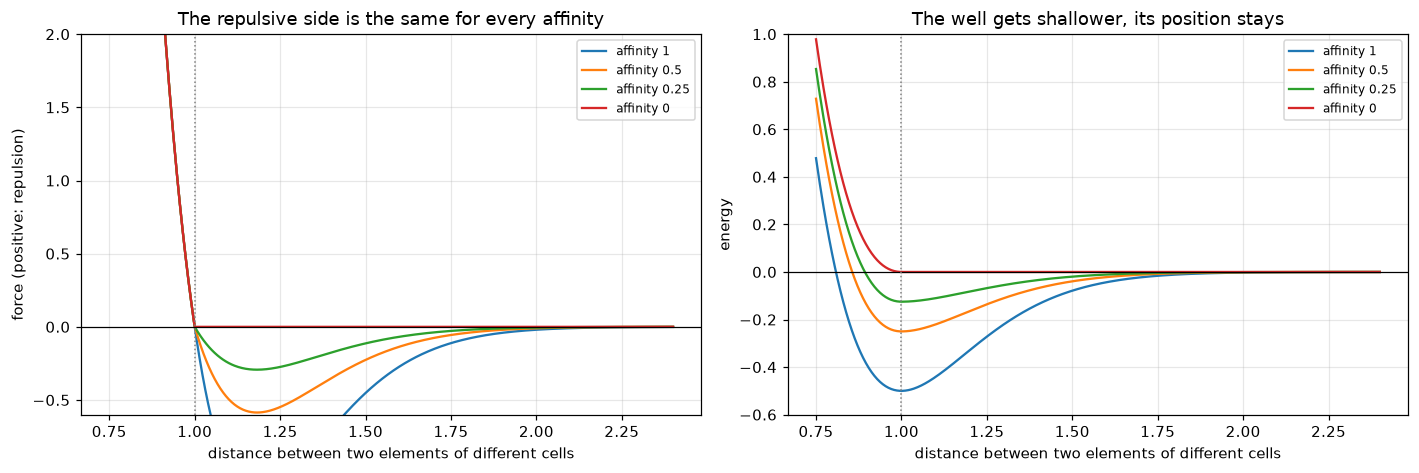

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def pair_force(r, well_depth=0.5, equilibrium_distance=1.0, steepness=2.0, affinity=1.0):
    # radial force between two elements of different cells, positive = repulsion
    t = np.exp(steepness * (1 - (r / equilibrium_distance) ** 2))
    force = 4 * well_depth * steepness / equilibrium_distance**2 * t * (t - 1) * r
    return np.where(force < 0, affinity * force, force)


def pair_energy(r, well_depth=0.5, equilibrium_distance=1.0, steepness=2.0, affinity=1.0):
    t = np.exp(steepness * (1 - (r / equilibrium_distance) ** 2))
    energy = well_depth * t * (t - 2)
    return np.where(r >= equilibrium_distance, affinity * energy, energy + (1 - affinity) * well_depth)


r = np.linspace(0.75, 2.4, 600)
fig, (ax_force, ax_energy) = plt.subplots(1, 2, figsize=(13, 4.4))
for affinity in (1.0, 0.5, 0.25, 0.0):
    ax_force.plot(r, pair_force(r, affinity=affinity), label=f"affinity {affinity:g}")
    ax_energy.plot(r, pair_energy(r, affinity=affinity), label=f"affinity {affinity:g}")

    # the energy is continuous and the force is minus its derivative, also across the minimum
    slope = -np.gradient(pair_energy(r, affinity=affinity), r)
    assert np.allclose(pair_force(r, affinity=affinity)[2:-2], slope[2:-2], rtol=0.02, atol=0.02)

for ax, name in ((ax_force, "force (positive: repulsion)"), (ax_energy, "energy")):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(1.0, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="distance between two elements of different cells", ylabel=name)
    ax.legend(fontsize=8)
ax_force.set(ylim=(-0.6, 2.0), title="The repulsive side is the same for every affinity")
ax_energy.set(ylim=(-0.6, 1.0), title="The well gets shallower, its position stays")
fig.tight_layout()

The energy needed to pull two elements apart is the affinity times the well depth. Calibrating adhesion
between two types is therefore one number per pair of types, and it does not change how the cells resist
compression.

## Cell sorting

The classic test of differential adhesion (Steinberg 1963): mix two kinds of cells that prefer their own kind,
let them move, and they sort.

36 motile cells of 19 elements each start as a 2D sheet in which the two types are assigned at random (24 of
one type and 12 of the other in this draw). Cells of the same type stick with the affinity 1. The affinity
between the two types is varied. The cells crawl in random directions inside a box with walls, which lets them
change neighbours.

The measure is the fraction of cell-cell contacts that joins cells of **different** types. Two cells count as
in contact when two of their elements are closer than 1.3 equilibrium distances.

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.cell_sorting
D=mechanics/micromechanics/docs/notebooks/data
for a in 0.1 0.5 1; do $E $a 200 > $D/cell_sorting_$a.csv; done
```

affinity    1: unlike contacts over the last quarter of the run 50% (random mixing 46%)
affinity  0.5: unlike contacts over the last quarter of the run 30% (random mixing 46%)
affinity  0.1: unlike contacts over the last quarter of the run 10% (random mixing 46%)


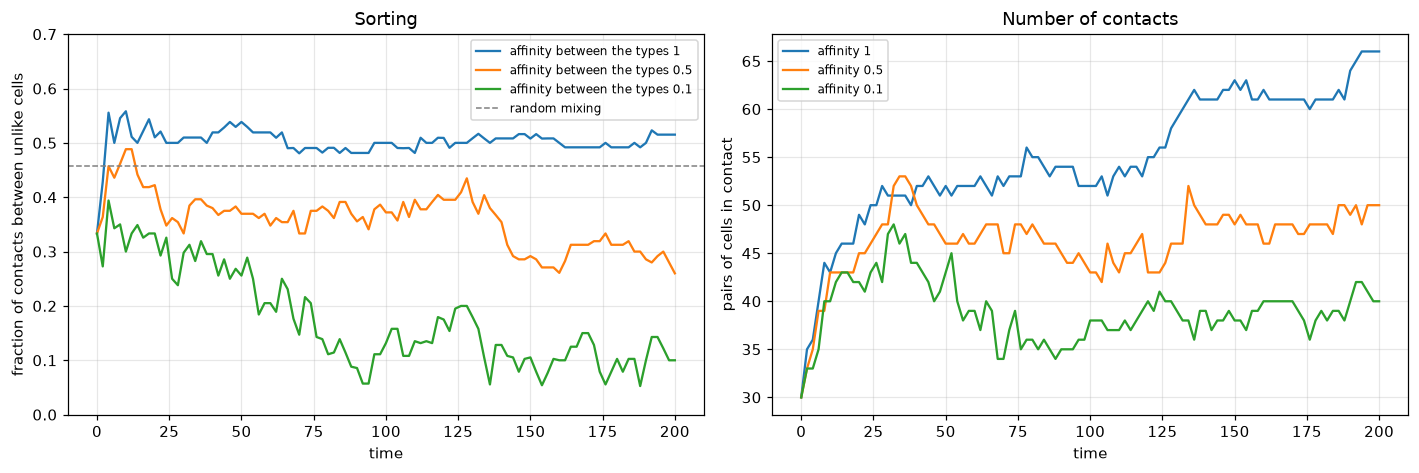

In [2]:
def load(name):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = {key: float(value) for key, value in (item.split("=") for item in header)}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1)


fig, (ax_fraction, ax_contacts) = plt.subplots(1, 2, figsize=(13, 4.4))
late = {}
for affinity in ("1", "0.5", "0.1"):
    params, table = load(f"cell_sorting_{affinity}.csv")
    ax_fraction.plot(table["time"], table["unlike_fraction"], label=f"affinity between the types {affinity}")
    ax_contacts.plot(table["time"], table["contacts"], label=f"affinity {affinity}")
    late[affinity] = table["unlike_fraction"][table["time"] >= 150].mean()

# if the types of touching cells were independent, this fraction of contacts would join unlike cells
n, second = params["cells"], params["of_second_type"]
random_mixing = 2 * second * (n - second) / (n * (n - 1))
ax_fraction.axhline(random_mixing, color="gray", linestyle="--", linewidth=1, label="random mixing")
ax_fraction.set(xlabel="time", ylabel="fraction of contacts between unlike cells", ylim=(0, 0.7), title="Sorting")
ax_fraction.legend(fontsize=8)
ax_contacts.set(xlabel="time", ylabel="pairs of cells in contact", title="Number of contacts")
ax_contacts.legend(fontsize=8)
fig.tight_layout()

for affinity, value in late.items():
    print(f"affinity {affinity:>4}: unlike contacts over the last quarter of the run {100 * value:.0f}% (random mixing {100 * random_mixing:.0f}%)")

assert abs(late["1"] - random_mixing) < 0.1, "with equal affinities the cells must stay mixed"
assert late["0.1"] < 0.5 * late["1"], "with a low affinity between the types the cells must sort"
assert late["0.1"] < late["0.5"] < late["1"] + 0.05

## Reading the result

- **With equal affinities the two types stay mixed**: the fraction of unlike contacts stays at the value of
  random mixing. The types are then labels without a mechanical meaning.
- **With a low affinity between the types the cells sort.** Unlike contacts fall to a fraction of the mixed
  value within the run. Nothing but the affinity was changed.
- **Fewer contacts in the sorted run**: cells of different types still touch when crowded together, but nothing
  holds them, so the sheet is less compact.

### Hints for calibration

- **Start from one type.** Set its `inter_well_depth` (through the adhesion ratio of `scale_to_elements`, 0.5 by
  default) so that two cells adhere without merging; see the two-cells notebook.
- **Then set affinities**, which only weaken attraction. A type's affinity to itself scales how cohesive a
  tissue of that type is; the affinity between two types scales how well they mix.
- **Affinities need not be symmetric in the input.** The value used for a pair is the geometric mean of the two
  entries, so 0.4 one way and 0.1 the other act as 0.2 both ways. If one entry is 0, the pair does not attract.
- **Different element sizes mix through their radii.** Types with more elements per cell have smaller elements;
  a contact between a coarse and a fine cell rests at the sum of the two element radii.

### Caveats

- **One sorting run per affinity**, 36 cells, one random start. The trend is clear; the numbers would scatter
  from seed to seed, and how far the sorting gets depends on how motile the cells are.
- **The stiffness of a contact is not the same on its two sides** when the affinity is below 1: compressing it
  meets the full well, stretching it the weakened one.
- **The steepness of the potential is shared by all types.**
- **Elements that belong to no cell** interact as if they were of the first type.
- **Walls are as hard as a contact with a cell of the element's own type.** A type with `inter_well_depth` 0
  feels neither other cells nor the soft wall; only the hard stop keeps it inside.